# Review and refine L1 first-arrival picks

The earlier picker propagates arrivals between receivers sorted by absolute offset and estimates noise over the first 10 ms, potentially including near-source signal. This notebook proposes independent local AIC variance-change picks, rather than forcing smooth moveout or agreement with an inversion.

**Candidates are not verified first breaks.** Local AIC can pick a later phase or noise; the original pick still anchors its search window. Red flags identify window-sensitive, low-contrast or large changes. A lack of flags does not prove correctness. Inspect the enlarged raw traces and use the explicit overrides below. This notebook does not overwrite the existing picks or rerun the inversion.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from utils import seg2_io, refraction, plotting
from utils.pick_refinement import refine_line

OUTPUT = Path('L1/pick_review')
gathers = seg2_io.read_line('L1/RF', source_x_overrides={'2026-10-08_RF_47.5m.dat': 47.5})
original = refraction.pick_line(gathers, v_min=150, v_max=1500, noise_window=0.010, threshold=3.0)
candidates, review = refine_line(gathers, original)
display(review.sort_values('window_spread_ms', ascending=False))
print('All candidates require visual confirmation; no fit residual was used to reposition them.')

Read 5 shot gathers from L1/RF:
  2026-10-08_RF_-5m.dat: source at -5.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_12.5m.dat: source at +12.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_27.5m.dat: source at +27.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_47.5m.dat: source at +47.5 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz
  2026-10-08_RF_60m.dat: source at +60.0 m, 12 receivers (0.0-55.0 m), 4096 samples at 8000 Hz


,shot_index,receiver_index,source_x_m,receiver_x_m,original_ms,candidate_ms,shift_ms,window_spread_ms,variance_std_ratio,review_flags
11,0,11,-5.0,55.0,51.500,44.875,-6.625,19.500,0.765083,window-sensitive (>2 ms); weak variance contra...
24,2,0,27.5,0.0,24.750,16.375,-8.375,18.250,1.890986,window-sensitive (>2 ms); weak variance contra...
38,3,2,47.5,10.0,47.625,49.625,2.000,15.125,0.288216,window-sensitive (>2 ms); weak variance contra...
20,1,8,12.5,40.0,33.500,32.375,-1.125,13.875,0.555775,window-sensitive (>2 ms); weak variance contra...
21,1,9,12.5,45.0,36.000,36.125,0.125,13.500,1.012675,window-sensitive (>2 ms); weak variance contra...
54,4,6,60.0,30.0,25.000,33.000,8.000,13.375,0.204797,window-sensitive (>2 ms); weak variance contra...
51,4,3,60.0,15.0,43.375,53.625,10.250,12.750,0.465420,window-sensitive (>2 ms); weak variance contra...
4,0,4,-5.0,20.0,22.875,29.750,6.875,12.625,0.663813,window-sensitive (>2 ms); weak variance contra...
49,4,1,60.0,5.0,49.375,55.625,6.250,12.375,0.396326,window-sensitive (>2 ms); weak variance contra...
22,1,10,12.5,50.0,39.250,41.625,2.375,11.750,0.527233,window-sensitive (>2 ms); weak variance contra...


All candidates require visual confirmation; no fit residual was used to reposition them.


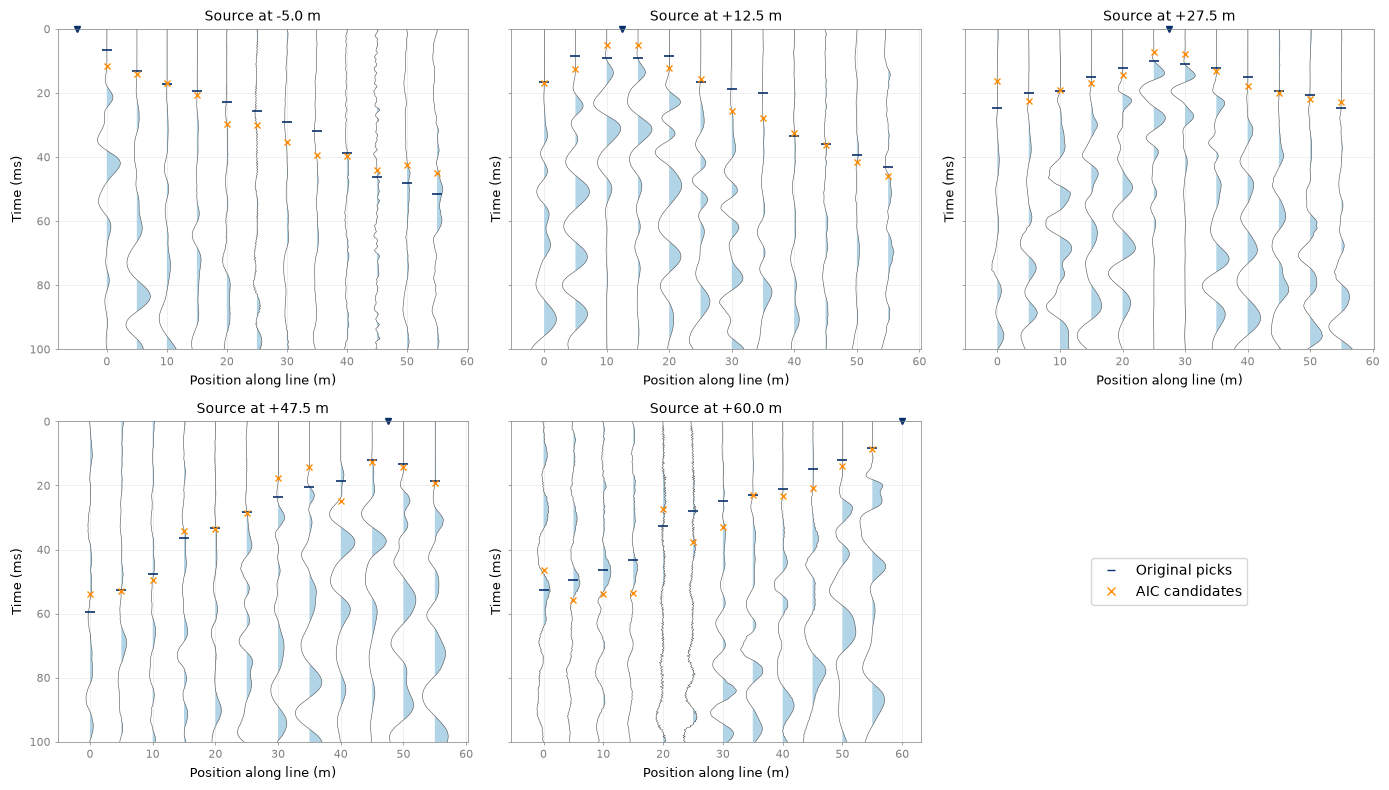

In [2]:
overview, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for i, (gather, ax) in enumerate(zip(gathers, axes.ravel())):
    plotting.plot_wiggle(gather, ax=ax, picks=original[i], t_max=0.10, fontsize=9, legend=False)
    ax.plot(gather.receiver_x, candidates[i]*1000, 'x', color='darkorange', ms=5, label='AIC candidates')
axes.ravel()[-1].axis('off')
axes.ravel()[-1].legend(handles=[
    plt.Line2D([], [], marker='_', color='#08306b', ls='', label='Original picks'),
    plt.Line2D([], [], marker='x', color='darkorange', ls='', label='AIC candidates')], loc='center')
overview.tight_layout()
plt.show()

## Trace-by-trace confirmation

Each panel shows a raw trace, the original pick and an AIC candidate. Choose the first reproducible signal departure from background noise, not a zero crossing or the largest peak. No filtering or inversion prediction is used here. Very weak/noisy arrivals, especially far-offset traces at source +47.5 m, may not support a reliable pick: discard them explicitly rather than inventing an onset. Equal offsets on opposite sides of a source need not have equal times.

The bottom cells accept `(shot_index, receiver_index): time_in_seconds` corrections; use `np.nan` to omit a trace. Refrapick can also load the candidate file for manual correction. Confirm the 47.5 m source coordinate against field notes.

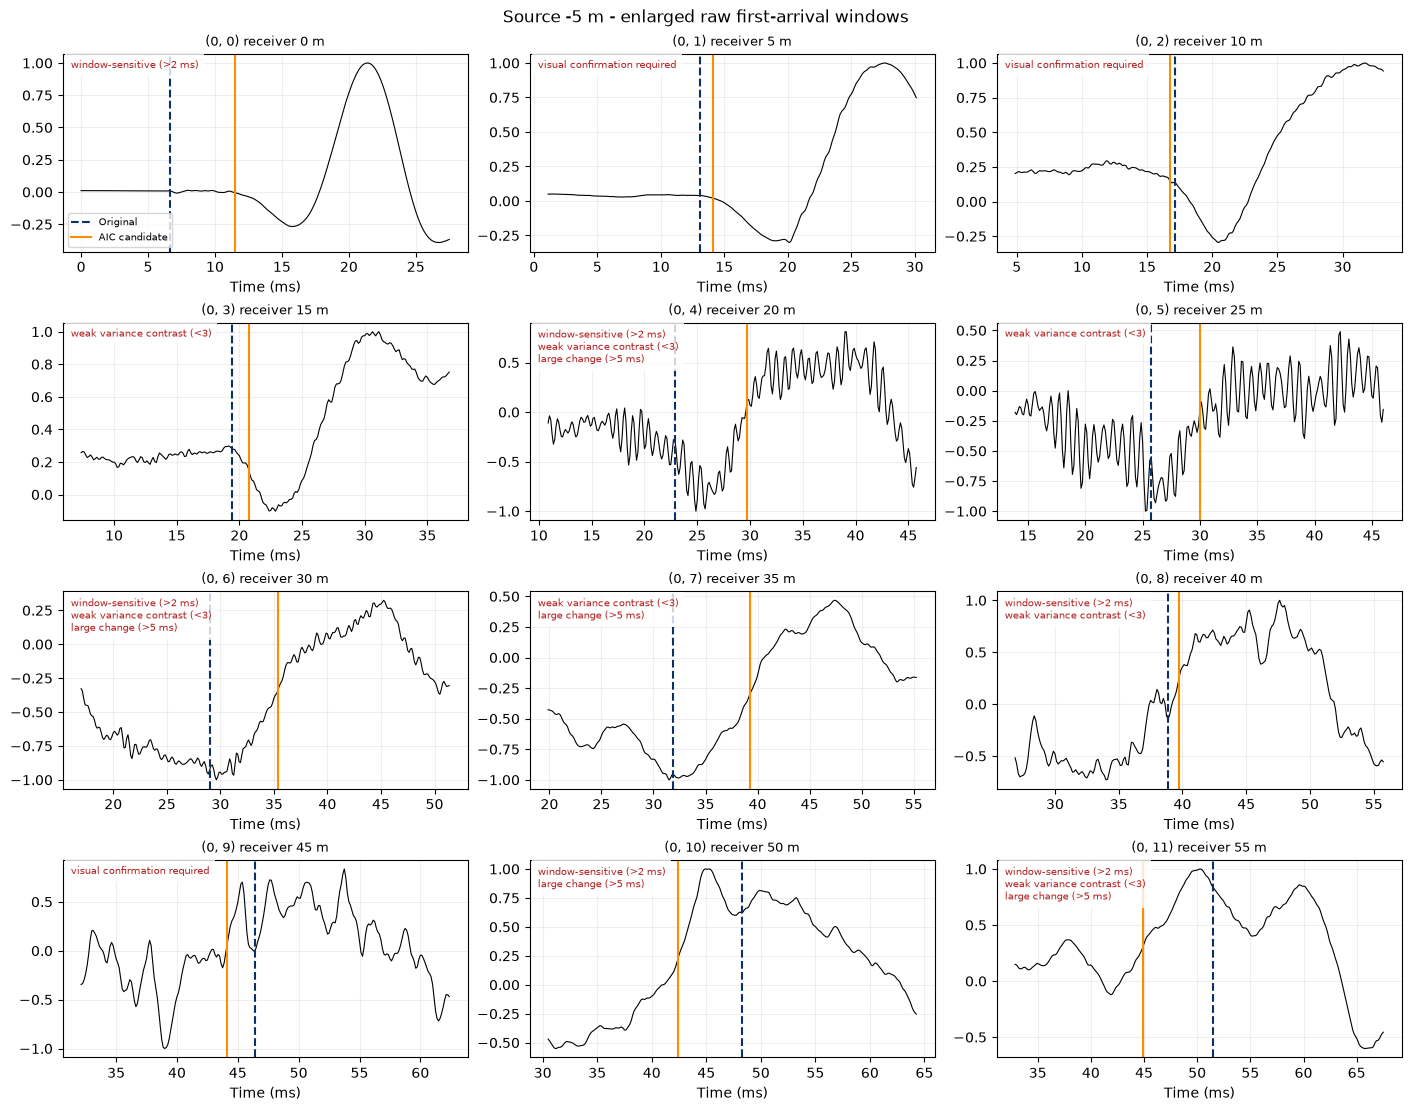

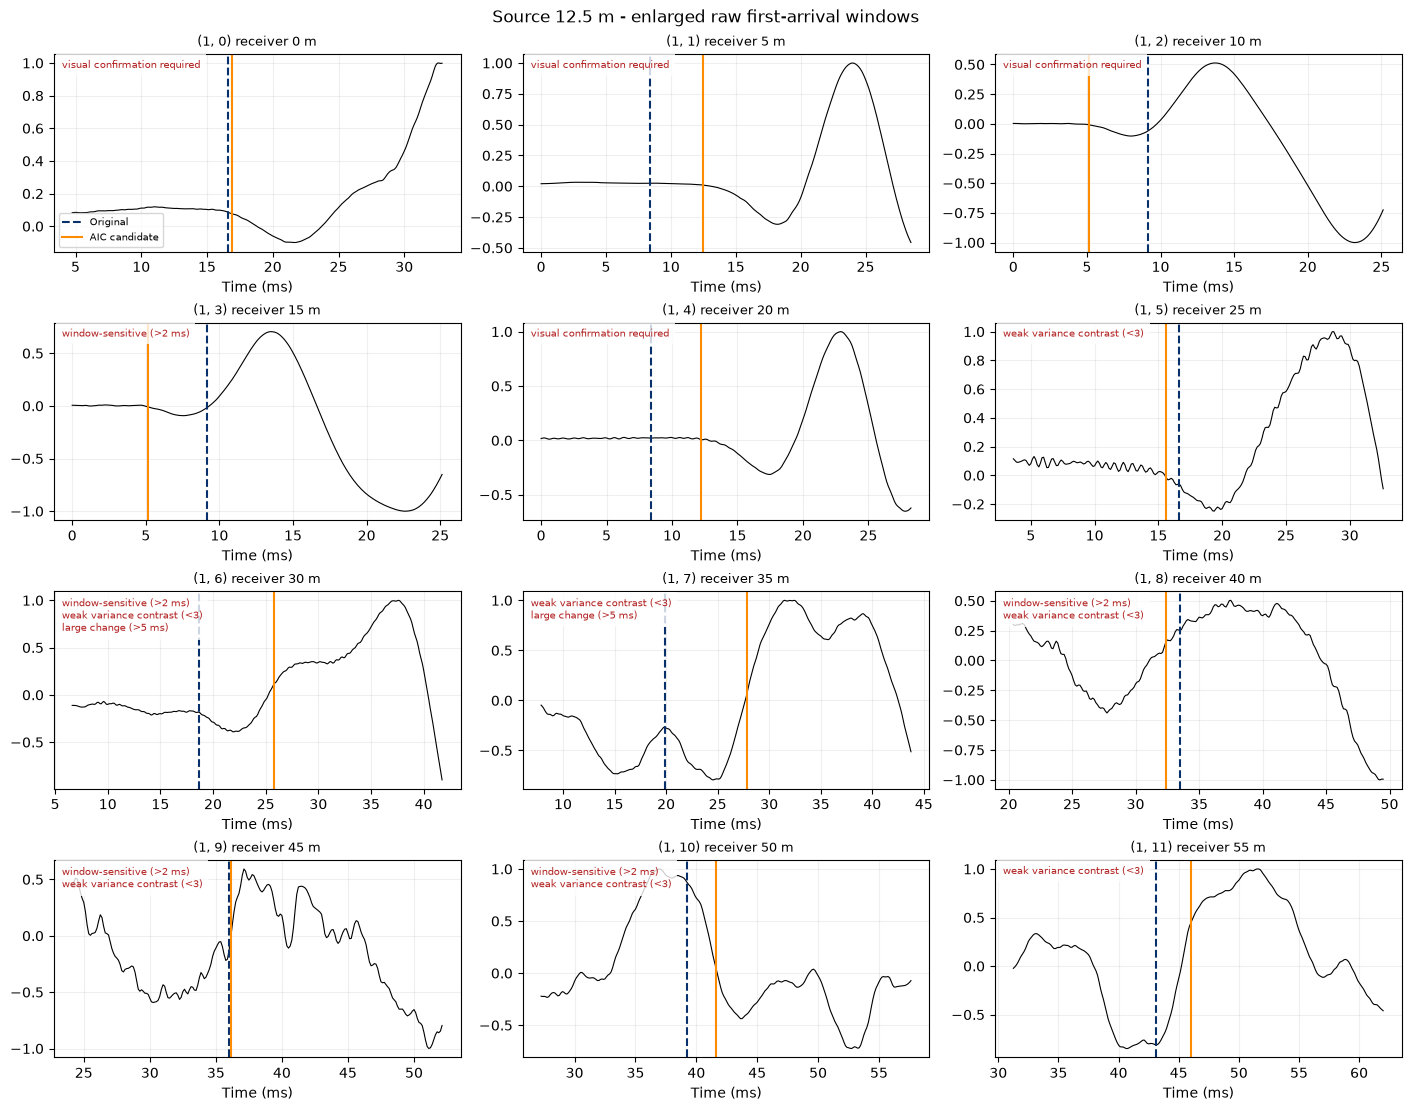

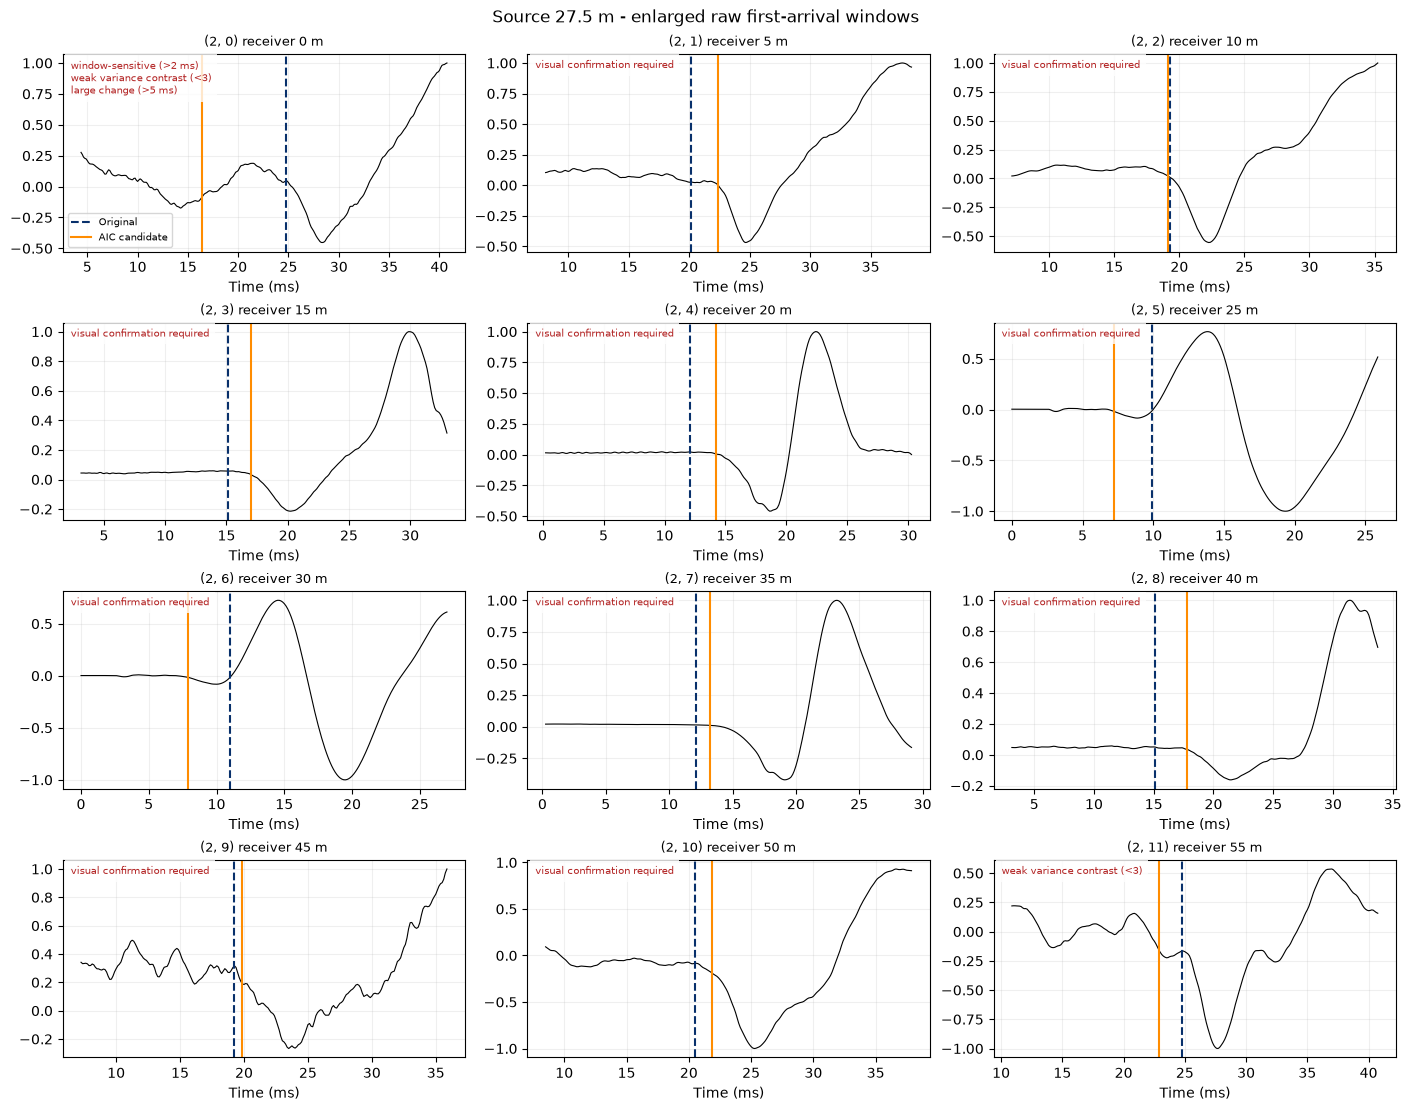

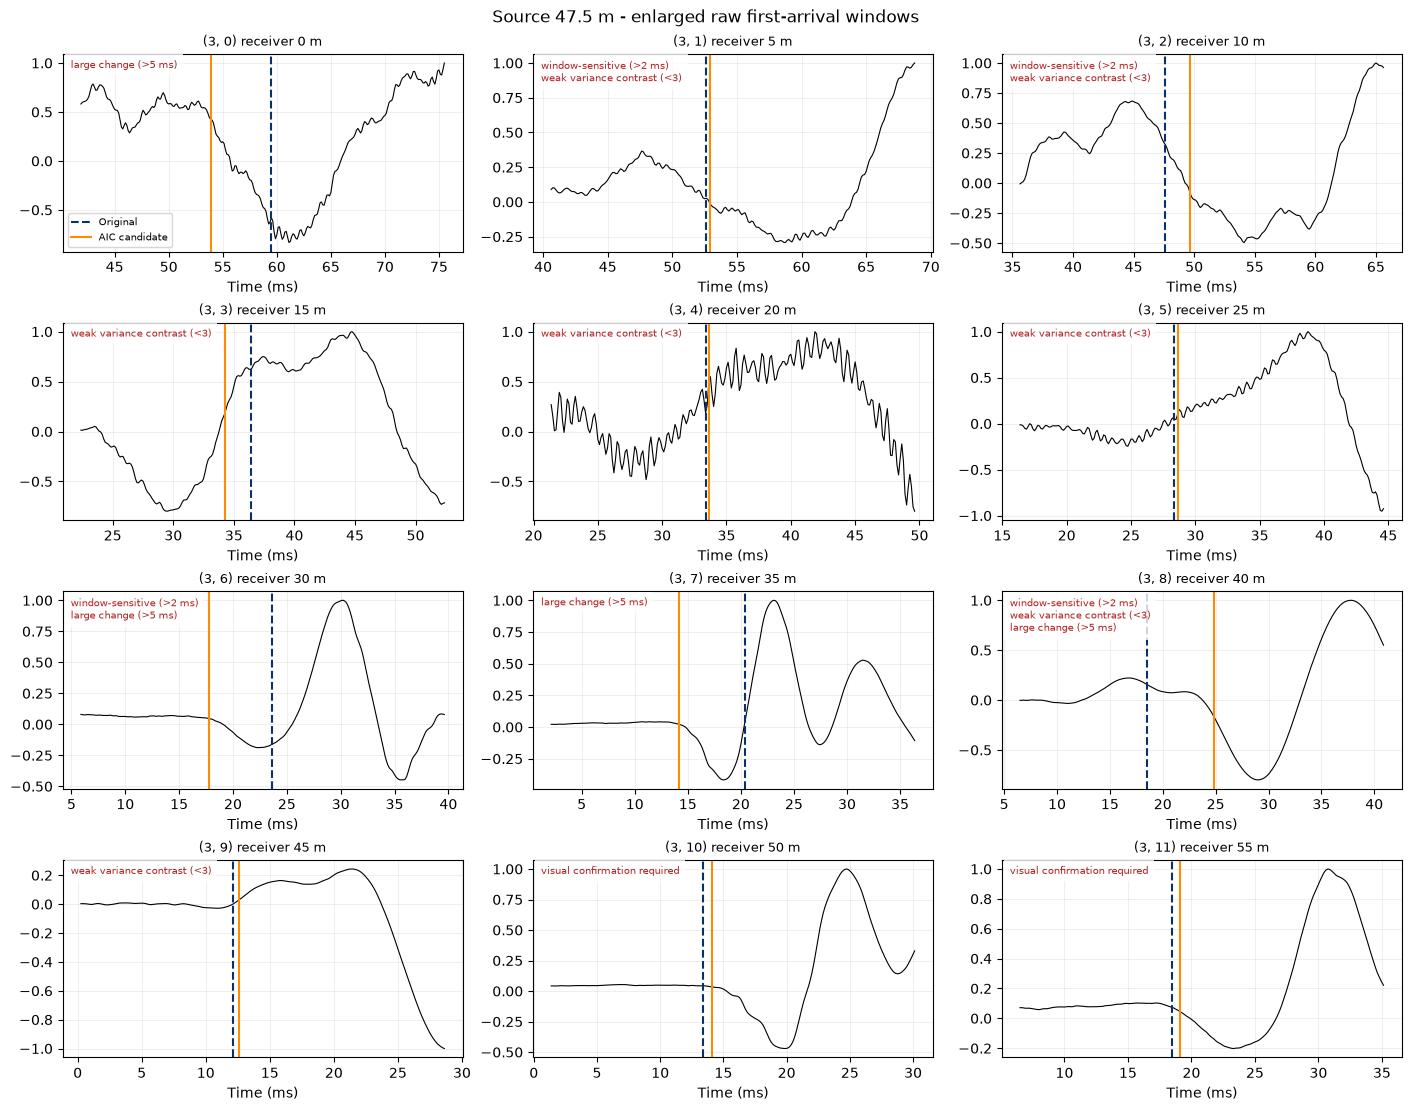

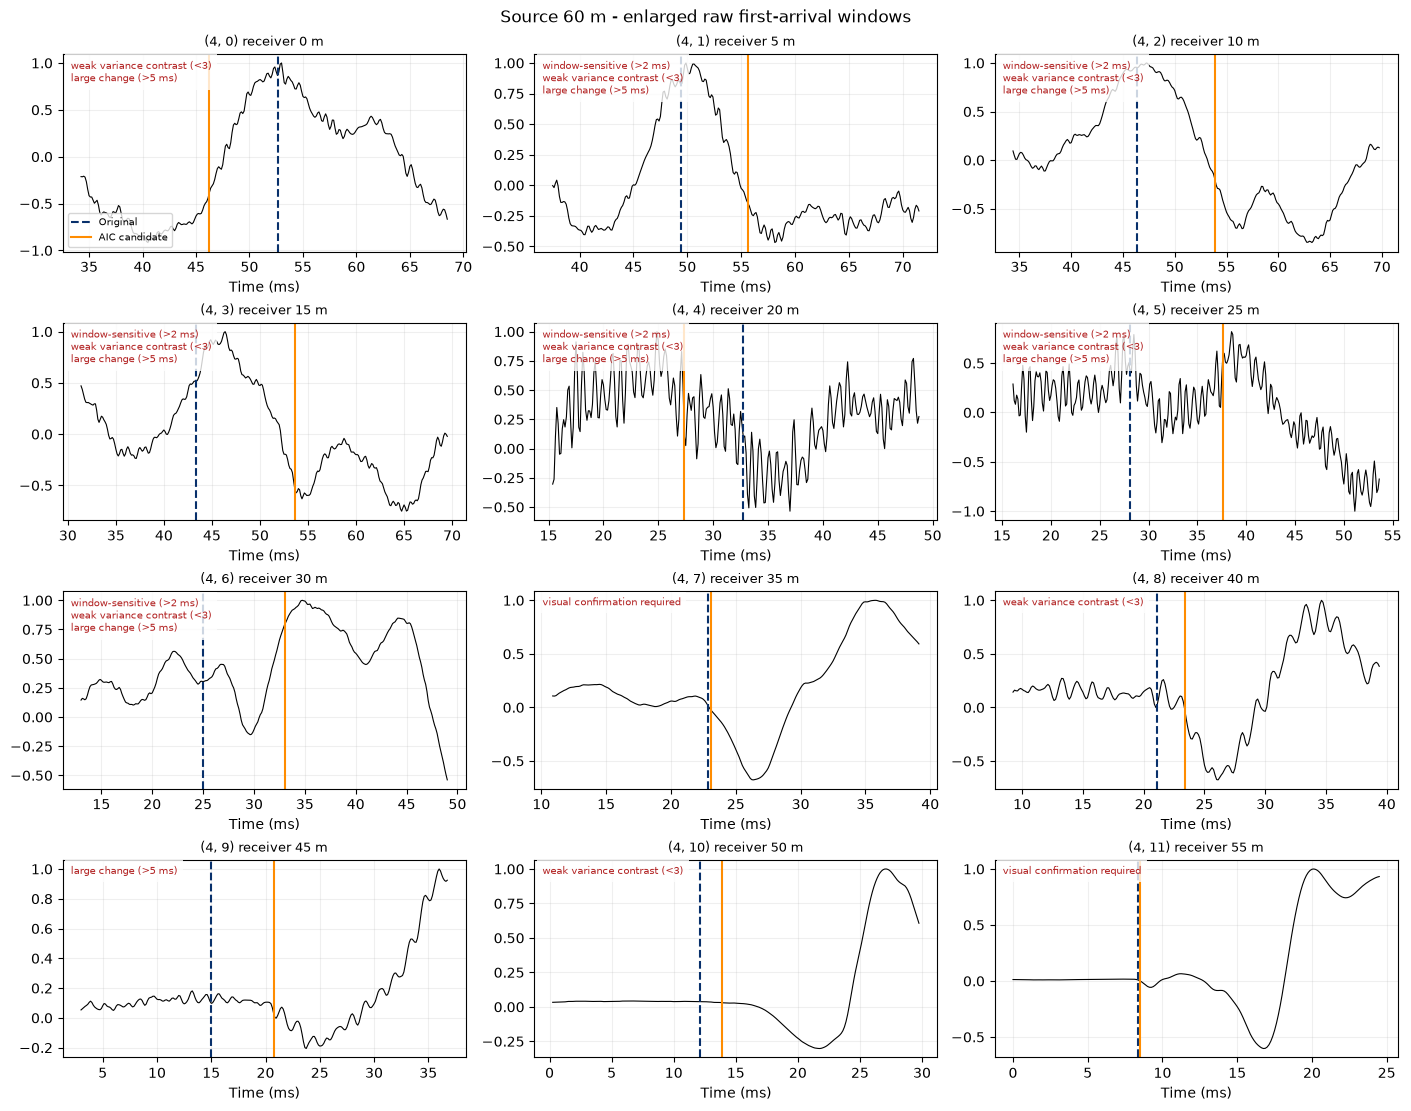

In [3]:
detail_figures = []
for shot_index, gather in enumerate(gathers):
    fig, axes = plt.subplots(4, 3, figsize=(14, 11), constrained_layout=True)
    fig.suptitle(f'Source {gather.source_x:g} m - enlarged raw first-arrival windows')
    for j, ax in enumerate(axes.ravel()):
        old, new = original[shot_index][j], candidates[shot_index][j]
        center = new if np.isfinite(new) else old
        lo = max(0, min(old, center)-0.012)
        hi = max(old, center)+0.016
        mask = (gather.time >= lo) & (gather.time <= hi)
        trace = gather.data[mask, j]
        scale = max(np.max(np.abs(trace)), np.finfo(float).tiny)
        ax.plot(gather.time[mask]*1000, trace/scale, color='black', lw=0.8)
        ax.axvline(old*1000, color='#08306b', ls='--', label='Original')
        if np.isfinite(new):
            ax.axvline(new*1000, color='darkorange', label='AIC candidate')
        record = review[(review.shot_index == shot_index) & (review.receiver_index == j)].iloc[0]
        ax.set_title(f'({shot_index}, {j}) receiver {gather.receiver_x[j]:g} m', fontsize=9)
        ax.set_xlabel('Time (ms)')
        ax.text(0.02, 0.97, record.review_flags.replace('; ', '\n'), transform=ax.transAxes,
                va='top', fontsize=7, color='firebrick', bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
        ax.grid(alpha=0.2)
    axes[0, 0].legend(fontsize=7, loc='lower left')
    detail_figures.append(fig)
    plt.show()

In [4]:
# Explicit human corrections, in seconds. np.nan excludes an unreliable trace.
MANUAL_OVERRIDES = {}
selected = [p.copy() for p in candidates]
for (shot_index, receiver_index), time in MANUAL_OVERRIDES.items():
    if not (0 <= shot_index < len(gathers) and 0 <= receiver_index < gathers[shot_index].n_receivers):
        raise ValueError('Manual override refers to an unknown trace.')
    if not np.isnan(time) and (not np.isfinite(time) or time <= 0 or time > gathers[shot_index].time[-1]):
        raise ValueError('Manual pick must be inside the recording, or np.nan to discard.')
    selected[shot_index][receiver_index] = time
review['selected_ms'] = [selected[int(row.shot_index)][int(row.receiver_index)]*1000 for row in review.itertuples()]
review['manually_overridden'] = [(int(row.shot_index), int(row.receiver_index)) in MANUAL_OVERRIDES for row in review.itertuples()]
OUTPUT.mkdir(parents=True, exist_ok=True)
review.to_csv(OUTPUT/'pick_comparison.csv', index=False)
data = refraction.build_traveltime_data(gathers, selected, pick_error=0.0035)
refraction.export_refrapy_picks(data, OUTPUT/'L1_AIC_candidates.sgt')
overview.savefig(OUTPUT/'pick_overview.png', dpi=180, bbox_inches='tight')
for i, fig in enumerate(detail_figures):
    fig.savefig(OUTPUT/f'shot_{i}_onset_review.png', dpi=150, bbox_inches='tight')
print(f'Saved {data.size()} candidate picks to {OUTPUT.resolve()}')
print('UNVERIFIED CANDIDATES: inspect and correct before inversion. Existing inversion results are unchanged.')

Traveltime data: 17 sensors, 60 picks


Saved 60 candidate picks to /home/orincon/seismic-refraction-analysis/L1/pick_review
UNVERIFIED CANDIDATES: inspect and correct before inversion. Existing inversion results are unchanged.
